# 03 · Gráficos e comparações por grupo — Nascidos vivos (SINASC/CE)

Visualizações para o relatório (histogramas com média e mediana, boxplots, correlações) e estatísticas descritivas **por grupo** (tipo de parto, sexo, tipo de
gravidez, duração da gestação, escolaridade da mãe, ano). As figuras são salvas em `../outputs/figuras`.

Requer ter rodado o notebook `01_preparacao_dados`.

In [37]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)

# %matplotlib inline  (já é o padrão no Jupyter)

CANDIDATOS = [
    Path("../../data/processed/Descritiva/SINASC_CE_PADRÃO_OURO_tratado.csv"),
]
CAMINHO = next((p for p in CANDIDATOS if p.exists()), None)
if CAMINHO is None:
    raise FileNotFoundError("Base tratada não encontrada. Rode o notebook 01 primeiro.")

df = pd.read_csv(
    CAMINHO,
    dtype={"CONTADOR": str, "CODMUNNASC": str, "CODMUNRES": str},
    parse_dates=["DTNASC"],
)

PASTA_TAB = Path("../outputs/tabelas")
PASTA_TAB.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
COR = "#4C78A8"
COR_MEDIA = "#E45756"
COR_MEDIANA = "#54A24B"


def br(x, casas=1):
    t = "{:,.{c}f}".format(x, c=casas)
    return t.replace(",", "#").replace(".", ",").replace("#", ".")


print("Base:", df.shape)

Base: (142568, 28)


## 1. Histogramas com média e mediana
Quando **média ≈ mediana**, a distribuição tende à simetria; quando a média é puxada para um lado, há assimetria (ex.: peso ao nascer tem cauda à esquerda por causa dos prematuros).

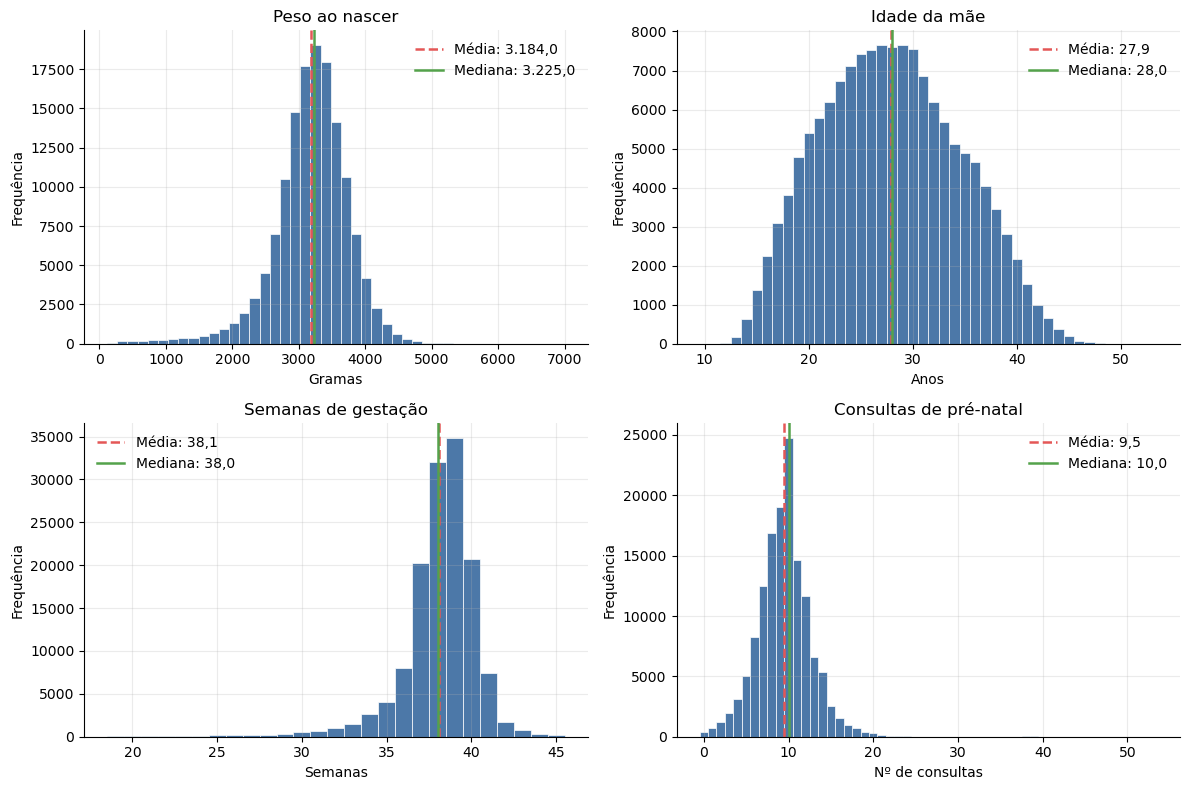

In [38]:
def histograma(ax, serie, titulo, xlabel, discreta=False, bins=40):
    s = serie.dropna()
    if discreta:
        bins = np.arange(s.min() - 0.5, s.max() + 1.5, 1)
    ax.hist(s, bins=bins, color=COR, edgecolor="white", linewidth=0.5)
    ax.axvline(s.mean(), color=COR_MEDIA, linestyle="--", linewidth=1.8, label="Média: " + br(s.mean()))
    ax.axvline(s.median(), color=COR_MEDIANA, linestyle="-", linewidth=1.8, label="Mediana: " + br(s.median()))
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequência")
    ax.legend(frameon=False)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
histograma(axes[0, 0], df["PESO"], "Peso ao nascer", "Gramas", bins=45)
histograma(axes[0, 1], df["IDADEMAE"], "Idade da mãe", "Anos", discreta=True)
histograma(axes[1, 0], df["SEMAGESTAC"], "Semanas de gestação", "Semanas", discreta=True)
histograma(axes[1, 1], df["CONSPRENAT"], "Consultas de pré-natal", "Nº de consultas", discreta=True)
fig.tight_layout()
plt.show()

## 2. Boxplots
A caixa vai de Q1 a Q3, a linha interna é a mediana, os "bigodes" chegam até o último valor dentro de 1,5·AIQ e os pontos são os outliers de Tukey.

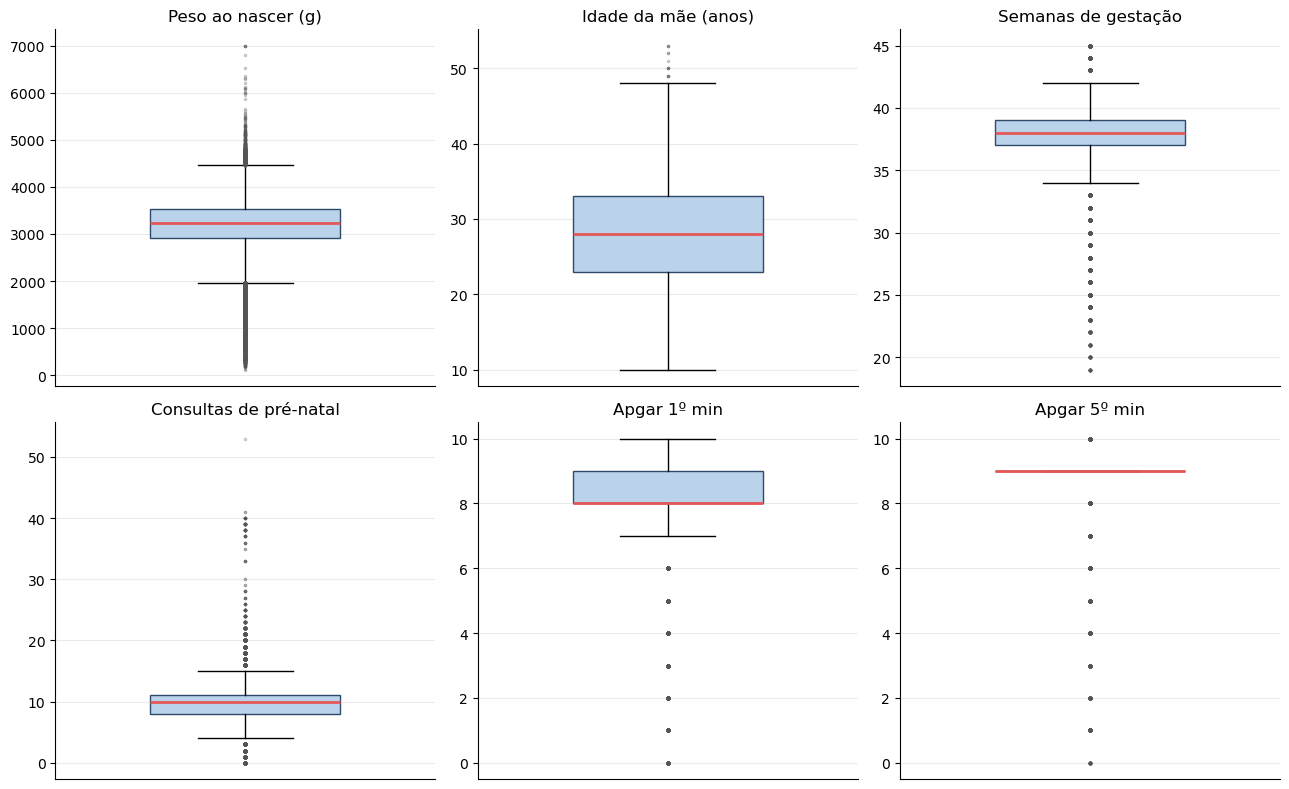

In [39]:
VARS_BOX = [("PESO", "Peso ao nascer (g)"), ("IDADEMAE", "Idade da mãe (anos)"), ("SEMAGESTAC", "Semanas de gestação"),
            ("CONSPRENAT", "Consultas de pré-natal"), ("APGAR1", "Apgar 1º min"), ("APGAR5", "Apgar 5º min")]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (col, nome) in zip(axes.ravel(), VARS_BOX):
    ax.boxplot(
        df[col].dropna(), patch_artist=True, widths=0.5,
        boxprops=dict(facecolor="#BBD3EA", edgecolor="#2F4B6B"),
        medianprops=dict(color=COR_MEDIA, linewidth=2),
        flierprops=dict(marker=".", markersize=3, alpha=0.35, markeredgecolor="#555555"),
    )
    ax.set_title(nome)
    ax.set_xticks([])
fig.tight_layout()
plt.show()

## 3. Estatísticas descritivas por grupo
`resumo_por_grupo` devolve n, média, mediana, desvio padrão, CV, Q1, Q3, mínimo e máximo. Grupos com menos de 30 registros são omitidos (estimativas instáveis).

In [40]:
def resumo_por_grupo(base, variavel, grupo, ordem=None, min_n=30):
    t = base.groupby(grupo)[variavel].agg(
        n="count", media="mean", mediana="median", dp="std",
        q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75),
        minimo="min", maximo="max",
    )
    t["cv_pct"] = t["dp"] / t["media"] * 100
    t = t[t["n"] >= min_n]
    if ordem is not None:
        t = t.reindex([o for o in ordem if o in t.index])
    t = t[["n", "media", "mediana", "dp", "cv_pct", "q1", "q3", "minimo", "maximo"]]
    t.columns = ["n", "Média", "Mediana", "DP", "CV (%)", "Q1", "Q3", "Mín.", "Máx."]
    t.index.name = None
    return t.round(2)


ORDENS = {
    "PARTO_DESC": ["Vaginal", "Cesáreo"],
    "SEXO_DESC": ["Masculino", "Feminino"],
    "GRAVIDEZ_DESC": ["Única", "Dupla", "Tripla ou mais"],
    "GESTACAO_DESC": ["< 22 sem", "22–27 sem", "28–31 sem", "32–36 sem", "37–41 sem", "≥ 42 sem"],
    "ESCMAE_DESC": ["Nenhuma", "1 a 3 anos", "4 a 7 anos", "8 a 11 anos", "12 anos ou mais"],
    "RACACOR_DESC": ["Branca", "Preta", "Amarela", "Parda", "Indígena"],
    "ANO": [2025, 2026],
}
ROTULOS_GRUPO = {
    "PARTO_DESC": "tipo de parto", "SEXO_DESC": "sexo", "GRAVIDEZ_DESC": "tipo de gravidez",
    "GESTACAO_DESC": "duração da gestação", "ESCMAE_DESC": "escolaridade da mãe",
    "RACACOR_DESC": "raça/cor", "ANO": "ano",
}

tabelas_grupo = {}
for g in ["PARTO_DESC", "SEXO_DESC", "GRAVIDEZ_DESC", "GESTACAO_DESC", "ESCMAE_DESC", "RACACOR_DESC", "ANO"]:
    t = resumo_por_grupo(df, "PESO", g, ORDENS[g])
    tabelas_grupo["peso_por_" + g.lower()] = t
    print("Peso ao nascer (g) por " + ROTULOS_GRUPO[g])
    display(t)

Peso ao nascer (g) por tipo de parto


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Vaginal,43635,3121.31,3170.0,563.47,18.05,2870.0,3460.0,135.0,6362.0
Cesáreo,98728,3211.75,3250.0,565.98,17.62,2925.0,3564.0,115.0,7000.0


Peso ao nascer (g) por sexo


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Masculino,72857,3234.21,3280.0,575.54,17.80,2955.0,3590.0,115.0,7000.0
Feminino,69682,3131.80,3170.0,552.43,17.64,2860.0,3468.0,172.0,7000.0


Peso ao nascer (g) por tipo de gravidez


...

,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Nenhuma,236,3030.00,3104.5,724.01,23.89,2719.0,3439.00,265.0,5406.0
1 a 3 anos,1264,3144.57,3185.0,615.22,19.56,2815.0,3531.25,200.0,5865.0
4 a 7 anos,13801,3142.98,3190.0,588.71,18.73,2844.0,3500.00,222.0,7000.0
8 a 11 anos,96255,3188.11,3228.0,568.79,17.84,2910.0,3535.00,115.0,7000.0
12 anos ou mais,29811,3195.06,3236.0,541.87,16.96,2926.0,3530.00,205.0,6116.0


Peso ao nascer (g) por raça/cor


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Branca,15961,3180.13,3225.0,544.25,17.11,2910.0,3516.0,230.0,7000.0
Preta,3648,3157.64,3202.0,583.36,18.47,2860.0,3520.0,135.0,7000.0
Amarela,396,3188.43,3209.0,559.57,17.55,2900.0,3509.0,810.0,6530.0
Parda,108024,3192.69,3230.0,559.10,17.51,2910.0,3535.0,115.0,7000.0
Indígena,543,3247.63,3275.0,480.99,14.81,2987.5,3517.5,1180.0,5504.0


Peso ao nascer (g) por ano


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
2025,107343,3189.16,3230.0,565.71,17.74,2910.0,3536.0,115.0,7000.0
2026,35221,3168.35,3210.0,569.96,17.99,2894.0,3516.0,135.0,7000.0


In [41]:
print("Idade da mãe (anos) por tipo de parto")
display(resumo_por_grupo(df, "IDADEMAE", "PARTO_DESC", ORDENS["PARTO_DESC"]))

print("Consultas de pré-natal por escolaridade da mãe")
display(resumo_por_grupo(df, "CONSPRENAT", "ESCMAE_DESC", ORDENS["ESCMAE_DESC"]))

Idade da mãe (anos) por tipo de parto


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Vaginal,43639,26.48,26.0,6.55,24.73,21.0,31.0,12.0,50.0
Cesáreo,98727,28.49,28.0,6.60,23.16,24.0,33.0,10.0,53.0


Consultas de pré-natal por escolaridade da mãe


,n,Média,Mediana,DP,CV (%),Q1,Q3,Mín.,Máx.
Nenhuma,229,8.46,9.0,3.71,43.84,6.0,11.0,0.0,22.0
1 a 3 anos,1181,9.06,9.0,3.41,37.62,7.0,11.0,0.0,33.0
4 a 7 anos,13262,8.79,9.0,3.35,38.14,7.0,11.0,0.0,40.0
8 a 11 anos,94478,9.50,10.0,3.13,33.00,8.0,11.0,0.0,53.0
12 anos ou mais,28764,9.69,10.0,3.11,32.09,8.0,11.0,0.0,40.0


### 3.1 Boxplots do peso ao nascer por grupo

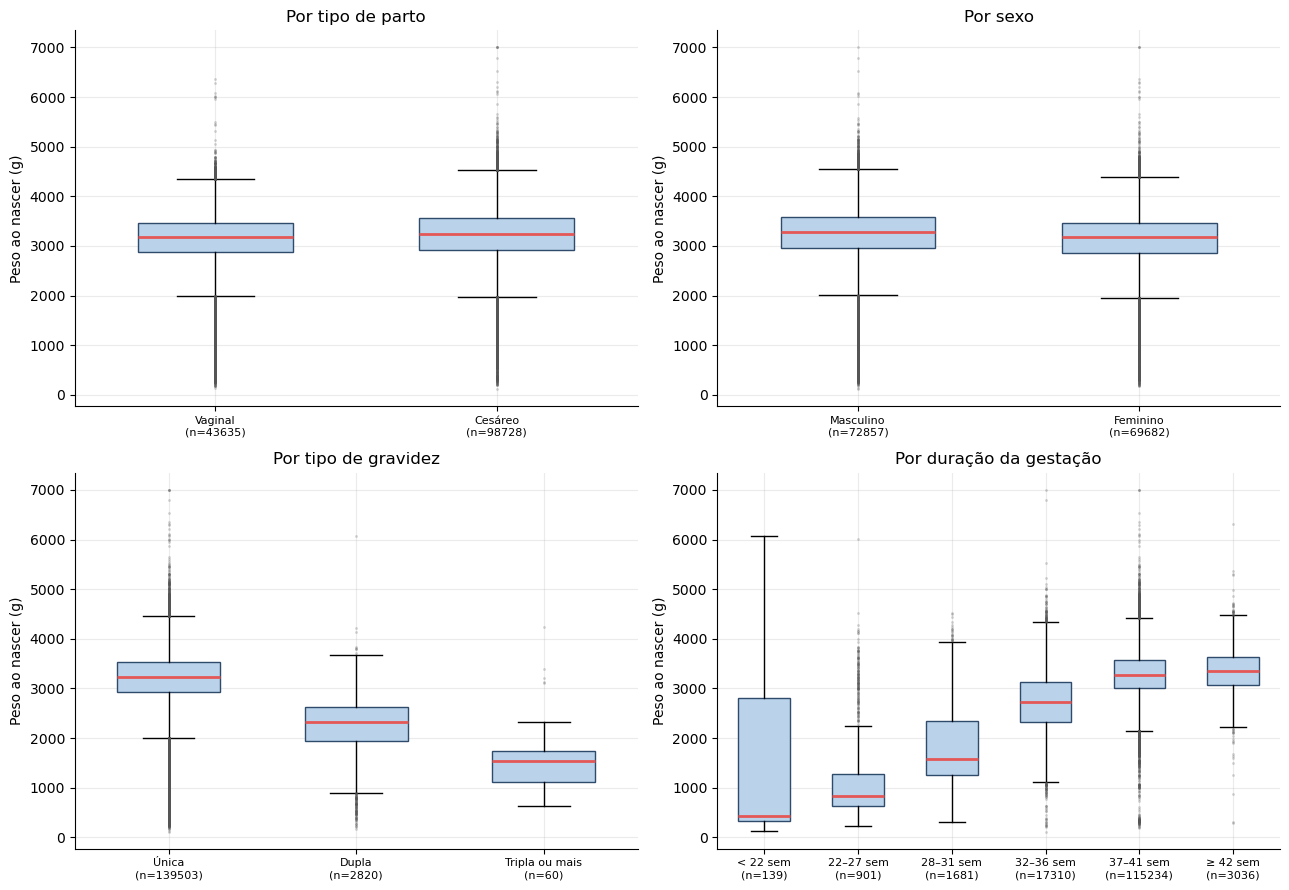

In [42]:
def boxplot_grupos(ax, base, variavel, grupo, ordem, titulo, min_n=30):
    dados, rotulos = [], []
    for o in ordem:
        s = base.loc[base[grupo] == o, variavel].dropna()
        if len(s) >= min_n:
            dados.append(s.values)
            rotulos.append(str(o) + "\n(n=" + str(len(s)) + ")")
    ax.boxplot(
        dados, patch_artist=True, widths=0.55,
        boxprops=dict(facecolor="#BBD3EA", edgecolor="#2F4B6B"),
        medianprops=dict(color=COR_MEDIA, linewidth=2),
        flierprops=dict(marker=".", markersize=2, alpha=0.25, markeredgecolor="#555555"),
    )
    ax.set_xticks(range(1, len(rotulos) + 1))
    ax.set_xticklabels(rotulos, fontsize=8)
    ax.set_title(titulo)
    ax.set_ylabel("Peso ao nascer (g)")


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
boxplot_grupos(axes[0, 0], df, "PESO", "PARTO_DESC", ORDENS["PARTO_DESC"], "Por tipo de parto")
boxplot_grupos(axes[0, 1], df, "PESO", "SEXO_DESC", ORDENS["SEXO_DESC"], "Por sexo")
boxplot_grupos(axes[1, 0], df, "PESO", "GRAVIDEZ_DESC", ORDENS["GRAVIDEZ_DESC"], "Por tipo de gravidez")
boxplot_grupos(axes[1, 1], df, "PESO", "GESTACAO_DESC", ORDENS["GESTACAO_DESC"], "Por duração da gestação")
fig.tight_layout()
plt.show()

## 4. Correlação entre variáveis quantitativas
Usamos **Spearman** (baseada em postos) como principal, porque várias variáveis são discretas ou assimétricas; Pearson é mostrado para comparação.
Lembrete: correlação não implica causalidade, e com n tão grande até correlações fracas ficam "significativas" — foque na **magnitude** (|ρ| < 0,3 fraca · 0,3–0,7 moderada · > 0,7 forte).

Spearman


,Peso,Idade mãe,Sem. gest.,Consultas,Apgar 1,Apgar 5
Peso,1.00,0.03,0.40,0.14,0.06,0.08
Idade mãe,0.03,1.00,-0.12,0.09,0.04,-0.00
Sem. gest.,0.40,-0.12,1.00,0.17,0.08,0.12
Consultas,0.14,0.09,0.17,1.00,0.05,0.08
Apgar 1,0.06,0.04,0.08,0.05,1.00,0.57
Apgar 5,0.08,-0.00,0.12,0.08,0.57,1.00


Pearson


,Peso,Idade mãe,Sem. gest.,Consultas,Apgar 1,Apgar 5
Peso,1.00,0.02,0.54,0.17,0.19,0.22
Idade mãe,0.02,1.00,-0.08,0.10,0.01,-0.00
Sem. gest.,0.54,-0.08,1.00,0.20,0.24,0.28
Consultas,0.17,0.10,0.20,1.00,0.07,0.10
Apgar 1,0.19,0.01,0.24,0.07,1.00,0.67
Apgar 5,0.22,-0.00,0.28,0.10,0.67,1.00


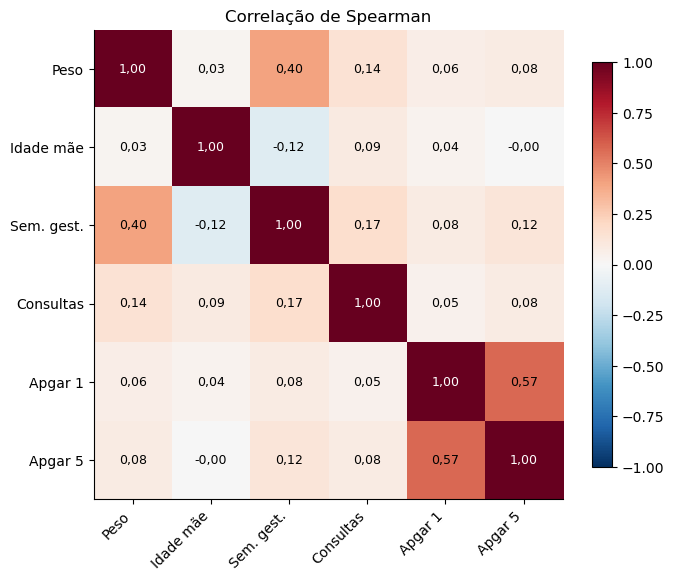

In [43]:
COLS_CORR = ["PESO", "IDADEMAE", "SEMAGESTAC", "CONSPRENAT", "APGAR1", "APGAR5"]
NOMES_CORR = ["Peso", "Idade mãe", "Sem. gest.", "Consultas", "Apgar 1", "Apgar 5"]

corr_spearman = df[COLS_CORR].corr(method="spearman")
corr_pearson = df[COLS_CORR].corr(method="pearson")
corr_spearman.index = corr_spearman.columns = NOMES_CORR
corr_pearson.index = corr_pearson.columns = NOMES_CORR

print("Spearman")
display(corr_spearman.round(2))
print("Pearson")
display(corr_pearson.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(NOMES_CORR)))
ax.set_xticklabels(NOMES_CORR, rotation=45, ha="right")
ax.set_yticks(range(len(NOMES_CORR)))
ax.set_yticklabels(NOMES_CORR)
for i in range(len(NOMES_CORR)):
    for j in range(len(NOMES_CORR)):
        v = corr_spearman.values[i, j]
        ax.text(j, i, br(v, 2), ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else "black")
ax.set_title("Correlação de Spearman")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

## 5. Apgar: distribuição das notas
O Apgar é discreto (0–10) e muito concentrado em 8–10, então barras são mais adequadas que histograma.

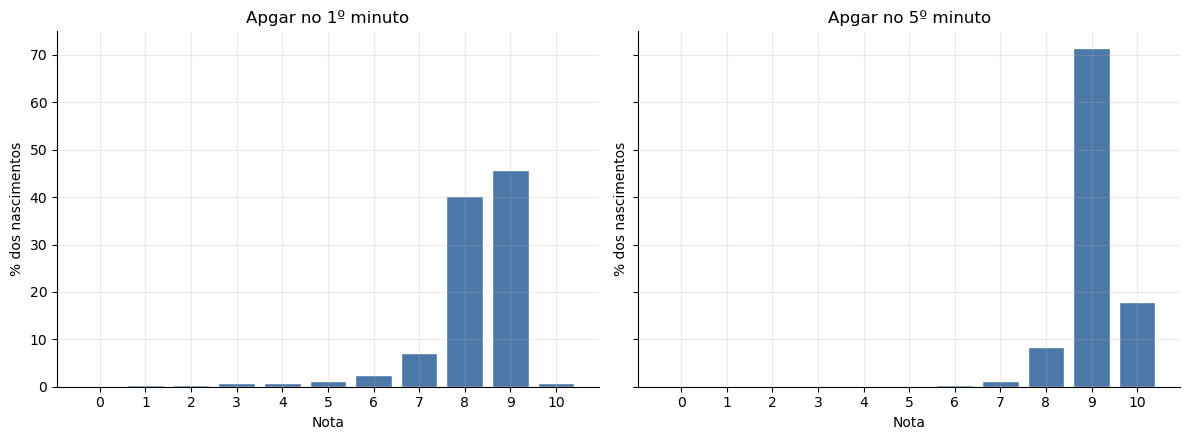

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (col, nome) in zip(axes, [("APGAR1", "Apgar no 1º minuto"), ("APGAR5", "Apgar no 5º minuto")]):
    f = df[col].dropna().astype(int).value_counts().sort_index()
    pct = f / f.sum() * 100
    ax.bar(f.index, pct.values, color=COR, edgecolor="white")
    ax.set_xticks(range(0, 11))
    ax.set_xlabel("Nota")
    ax.set_title(nome)
    ax.set_ylabel("% dos nascimentos")
fig.tight_layout()
plt.show()

## 6. Indicadores por ano
Proporções (%) entre os registros com informação. **2026 é parcial** (até o fim de maio), então compare proporções, não contagens.

In [45]:
ind = df.groupby("ANO")[["BAIXO_PESO", "PREMATURO", "CESAREO"]].mean() * 100
ind.loc["Total"] = df[["BAIXO_PESO", "PREMATURO", "CESAREO"]].mean() * 100
ind.columns = ["Baixo peso (%)", "Prematuridade (%)", "Parto cesáreo (%)"]
ind["Nascimentos (n)"] = list(df["ANO"].value_counts().sort_index().values) + [len(df)]
ind.index = [str(i) for i in ind.index]
display(ind.round(2))

,Baixo peso (%),Prematuridade (%),Parto cesáreo (%),Nascimentos (n)
2025,8.80,14.00,69.11,107346
2026,9.54,15.95,70.07,35222
Total,8.98,14.48,69.35,142568


## 7. Exportação das tabelas por grupo

In [46]:
for nome, tabela in tabelas_grupo.items():
    tabela.to_csv(PASTA_TAB / (nome + ".csv"), sep=";", decimal=",", encoding="utf-8-sig")
corr_spearman.round(3).to_csv(PASTA_TAB / "correlacao_spearman.csv", sep=";", decimal=",", encoding="utf-8-sig")
corr_pearson.round(3).to_csv(PASTA_TAB / "correlacao_pearson.csv", sep=";", decimal=",", encoding="utf-8-sig")
ind.round(2).to_csv(PASTA_TAB / "indicadores_por_ano.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("Tabelas salvas em:", PASTA_TAB.resolve())

Tabelas salvas em: C:\Users\italo\OneDrive\Ambiente de Trabalho\Sinasc\Nascidos_Vivos\notebooks\outputs\tabelas
